0.138561994


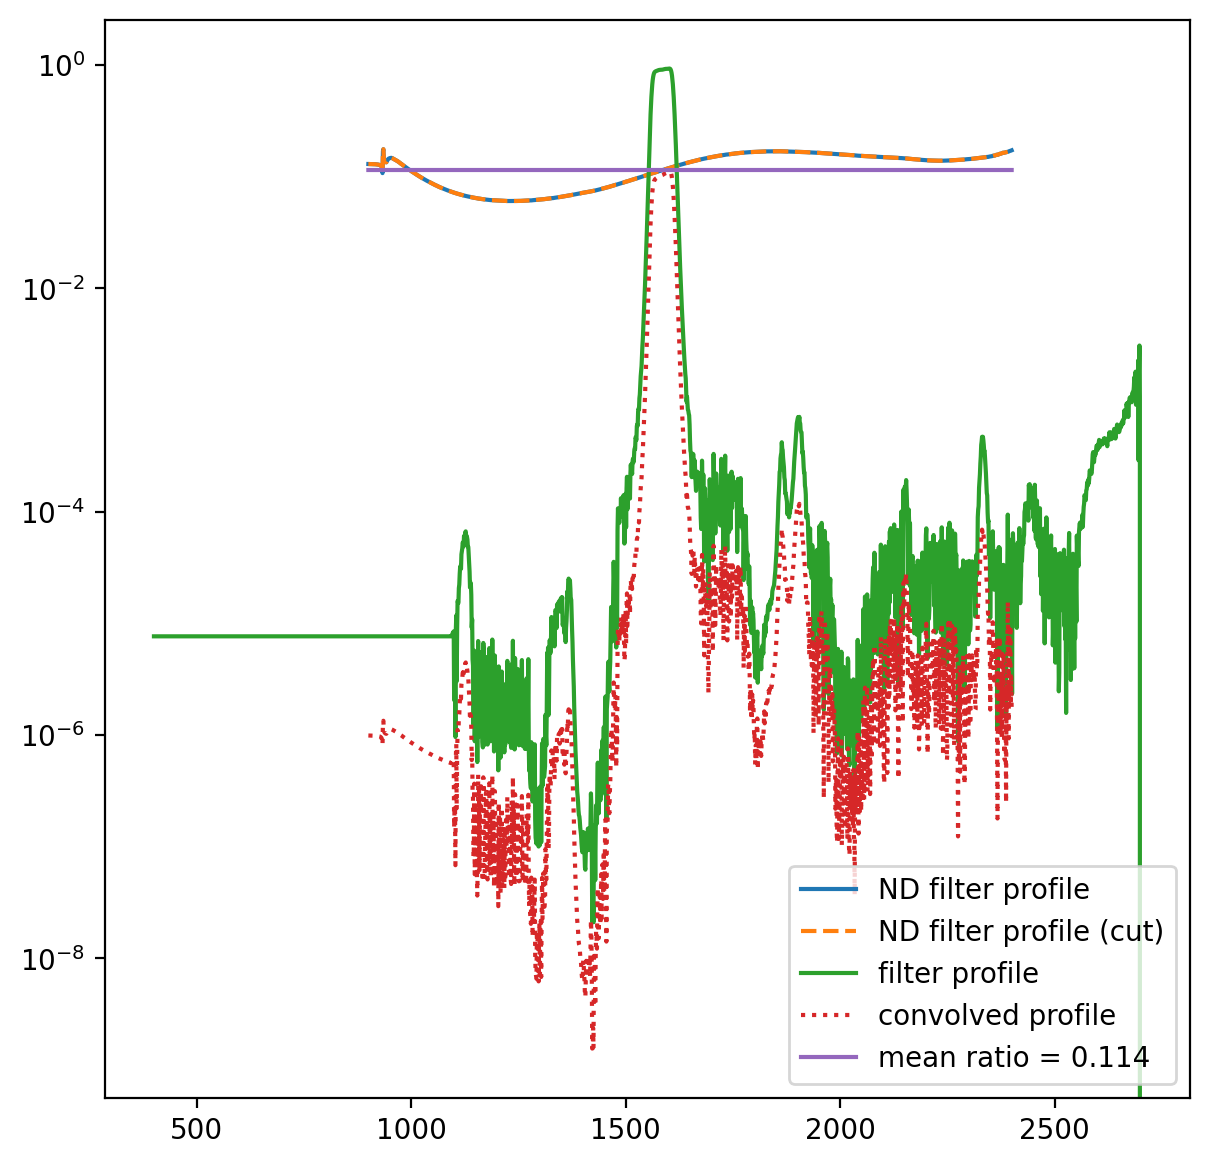

0.11434501897641787

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from SIRP.irdis_filters import get_filter_path 


def get_ratio_for_nd_filter(wave_filter, nd_filter, L_or_R, plot = False):
    
    # get transmittsion profile
    if 'DB' in wave_filter:
        wave_filter = wave_filter.replace('DB', 'D')

    if 'BB' in wave_filter:
        wave_filter = wave_filter.replace('BB', 'B')

    trans_profile_file = get_filter_path('SPHERE_IRDIS_' + wave_filter + '.dat')

    if np.loadtxt(trans_profile_file).transpose().shape[0] == 3:
        trans_wave, trans1, trans2 = np.loadtxt(trans_profile_file).transpose()
        if L_or_R == 'LEFT':
            trans = trans1
        elif L_or_R == 'RIGHT':
            trans = trans2
        else:
            raise ValueError()

    elif np.loadtxt(trans_profile_file).transpose().shape[0] == 2:
        trans_wave, trans = np.loadtxt(trans_profile_file).transpose()

    else:
        raise ValueError()


    # get the ndfilter:
    nd_file = get_filter_path('SPHERE_CPI_ND.dat')
    ND_DF = pd.DataFrame(np.loadtxt(nd_file), columns=['wavelength', 'ND0.0','ND1.0','ND2.0','ND3.5'])

    nd_wave = ND_DF['wavelength'].values
    nd_trans = ND_DF['ND' + nd_filter.split('_')[-1]].values

    nd_wave_start, nd_wave_stop = np.nanmin(nd_wave), np.nanmax(nd_wave)

    start = max(nd_wave.min(), trans_wave.min())
    end = min(nd_wave.max(), trans_wave.max())


    # Create masks
    mask_A = (nd_wave >= start) & (nd_wave <= end)
    mask_B = (trans_wave >= start) & (trans_wave <= end)

    # Apply masks
    nd_wave_cut = nd_wave[mask_A]
    nd_trans_cut = nd_trans[mask_A]

    trans_wave_B_cut = trans_wave[mask_B]
    trans_cut = trans[mask_B]


    # nd_trans_cut = nd_trans_cut[trans_cut >= 1e-3]
    # nd_wave_cut = nd_wave_cut[trans_cut >= 1e-3]
    # trans_wave_B_cut = trans_wave_B_cut[trans_cut >= 1e-3]
    # trans_cut = trans_cut[trans_cut >= 1e-3]

    ratio2 = np.median(nd_trans_cut) 
    print(ratio2)

    convoluted_trans = nd_trans_cut * trans_cut


    # as the profile is sampled by 1 Angstrom, the integral is simply the sum of the transmission
    trans_integrate = np.nansum(trans_cut)
    convoluted_trans_integrate = np.nansum(convoluted_trans)

    ratio = convoluted_trans_integrate/trans_integrate

    if plot:
        plt.figure(figsize = (7,7), dpi = 200)
        plt.plot(nd_wave, nd_trans, label = 'ND filter profile')
        plt.plot(nd_wave_cut, nd_trans_cut, label = 'ND filter profile (cut)', ls='--')

        plt.plot(trans_wave, trans, label = 'filter profile')
        plt.plot(nd_wave_cut, convoluted_trans, label = 'convolved profile', ls=':')
        plt.plot(nd_wave_cut, np.ones(len(nd_wave_cut))*ratio, label = 'mean ratio = {:1.3f}'.format(ratio))
        plt.yscale('log')
        plt.legend()
        plt.show()


    return ratio


get_ratio_for_nd_filter('DB_H23', '1.0', 'LEFT', True)

In [3]:
1/0.138561994

7.216986210518882